# 📊 Step 7 – Statistical Analysis

## Objective

The objective of this step is to statistically validate the patterns
identified during exploratory data analysis and determine whether
differences and relationships observed in customer purchase behavior
are statistically meaningful.

The analysis focuses on customer demographics, city category,
city tenure, occupation and purchase amount.

## Statistical Methods

- Independent Samples T-Test
- One-Way ANOVA
- Correlation Analysis
- Confidence Intervals
- Effect Size
- Assumption Testing    

# Business Questions

## "What business question am I trying to answer?"

- Question 1 — Gender

Do male and female customers have significantly different average purchase amounts?

- Question 2 — Marital Status

Do married and single customers have significantly different average purchase amounts?

- Question 3 — Age

Is average purchase significantly different across age groups?

- Question 4 — City

Is average purchase significantly different across City Categories A, B and C?

- Question 5 — City Tenure

Is customer purchase associated with the number of years they have stayed in their current city?

- Question 6 — Occupation

Is occupation associated with purchase amount?

# Hypotheses

## Test 1 — Gender

H₀: There is no significant difference in average purchase between male and female customers.

H₁: There is a significant difference in average purchase between male and female customers.

## Test 2 — Marital Status

H₀: There is no significant difference in average purchase between married and single customers.

H₁: There is a significant difference in average purchase between married and single customers.

## Test 3 — Age

H₀: Mean purchase is the same across all age groups.

H₁: At least one age group has a different mean purchase.

## Test 4 — City

H₀: Mean purchase is the same across City Categories A, B and C.

H₁: At least one city category has a different mean purchase.

## Test 5 — City Tenure

H₀: There is no statistically significant relationship between city tenure and purchase amount.

H₁: There is a statistically significant relationship between city tenure and purchase amount.

## Test 6 — Occupation

The brief requests a correlation analysis involving occupation.

# 🔀 Import Libraries

In [1]:
!pip install mysql-connector-python

In [2]:
import mysql.connector
import pandas as pd
import numpy as np

from scipy import stats
from scipy.stats import (
    ttest_ind,
    f_oneway,
    pearsonr,
    spearmanr,
    levene
)

import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
print("Statistical libraries imported successfully!")

Statistical libraries imported successfully!


In [3]:
# Replace placeholders with your local MySQL credentials before running

connection = mysql.connector.connect(
    host="*****",
    user="*****",
    password="*****",
    database="black_friday_db"
)

In [4]:
if connection.is_connected():
    print("MySQL connection successful!")


MySQL connection successful!


In [5]:
query = """
SELECT *
FROM black_friday_data;
"""

df_black_friday = pd.read_sql(query, connection)

C:\Users\Megha Solanki\AppData\Local\Temp\ipykernel_12196\2433544625.py:6: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_black_friday = pd.read_sql(query, connection)


In [14]:
df_black_friday.head()

,Transaction_ID,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1,1000001,P00069042,F,0-17,10,A,2,0,3,,,8370
1,2,1000001,P00248942,F,0-17,10,A,2,0,1,6,14,15200
2,3,1000001,P00087842,F,0-17,10,A,2,0,12,,,1422
3,4,1000001,P00085442,F,0-17,10,A,2,0,12,14,,1057
4,5,1000002,P00285442,M,55+,16,C,4+,0,8,,,7969


In [8]:
df_black_friday.shape

(550068, 13)

In [9]:
df_black_friday.columns

Index(['Transaction_ID', 'User_ID', 'Product_ID', 'Gender', 'Age',
       'Occupation', 'City_Category', 'Stay_In_Current_City_Years',
       'Marital_Status', 'Product_Category_1', 'Product_Category_2',
       'Product_Category_3', 'Purchase'],
      dtype='object')

# Test 1 — Gender T-Test

Do male and female customers have different average purchase values?

In [13]:
gender_summary = (
    df_black_friday.groupby("Gender")["Purchase"]
      .agg(["count", "mean", "std"])
)

gender_summary

,count,mean,std
Gender,,,
F,135809,8734.565765,4767.233289
M,414259,9437.526040,5092.186210


# 📊 Box Plot

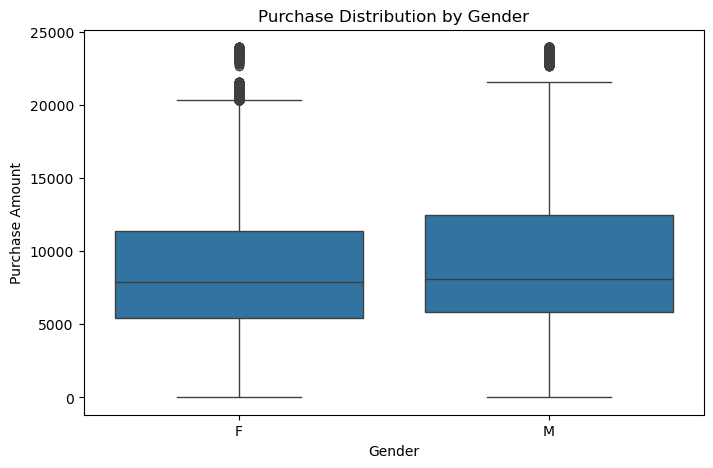

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_black_friday,
    x="Gender",
    y="Purchase"
)

plt.title("Purchase Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Purchase Amount")

plt.show()

## 📱 t-test

In [22]:
male_purchase = df_black_friday.loc[
    df_black_friday["Gender"] == "M",
    "Purchase"
]

female_purchase = df_black_friday.loc[
    df_black_friday["Gender"] == "F",
    "Purchase"
]

t_stat, p_value = ttest_ind(
    male_purchase,
    female_purchase,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 46.35824866962607
P-value: 0.0


## Decision rule

In [25]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Reject H0


## Business interpretation template

### If p < 0.05:

The difference in average purchase between male and female customers is statistically significant. Therefore, gender appears to be associated with differences in purchase behavior in this dataset.

### If p >= 0.05:

The analysis does not provide sufficient statistical evidence that average purchase differs between male and female customers.

## The mean difference:

In [27]:
mean_male = male_purchase.mean()
mean_female = female_purchase.mean()

mean_diff = mean_male - mean_female

print("Mean difference:", mean_diff)

Mean difference: 702.9602753167892


## Welch confidence interval

In [28]:
n1 = len(male_purchase)
n2 = len(female_purchase)

s1 = male_purchase.std()
s2 = female_purchase.std()

se = np.sqrt((s1**2 / n1) + (s2**2 / n2))

df_welch = (
    ((s1**2 / n1) + (s2**2 / n2))**2 /
    (
        ((s1**2 / n1)**2 / (n1 - 1)) +
        ((s2**2 / n2)**2 / (n2 - 1))
    )
)

critical_value = stats.t.ppf(
    0.975,
    df_welch
)

lower = mean_diff - critical_value * se
upper = mean_diff + critical_value * se

print("95% CI:", lower, "to", upper)

95% CI: 673.2399199578947 to 732.6806306756837


# Test 2 — Marital Status T-Test

In [30]:
df_black_friday["Marital_Status_Label"] = df_black_friday["Marital_Status"].map({
    0: "Single",
    1: "Married"
})

In [32]:
marital_summary = (
    df_black_friday.groupby("Marital_Status_Label")["Purchase"]
      .agg(["count", "mean", "std"])
)

marital_summary

,count,mean,std
Marital_Status_Label,,,
Married,225337,9261.174574,5016.897378
Single,324731,9265.907619,5027.347859


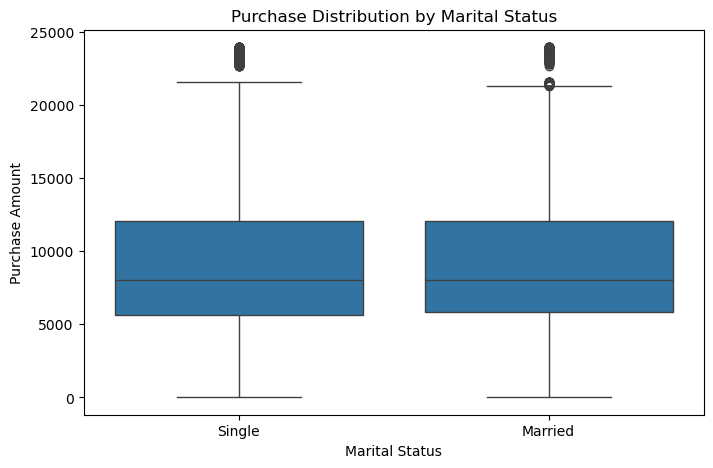

In [34]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_black_friday,
    x="Marital_Status_Label",
    y="Purchase"
)

plt.title("Purchase Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Purchase Amount")

plt.show()

In [38]:
single_purchase = df_black_friday.loc[
    df_black_friday["Marital_Status_Label"] == "Single",
    "Purchase"
]

married_purchase = df_black_friday.loc[
    df_black_friday["Marital_Status_Label"] == "Married",
    "Purchase"
]

t_stat, p_value = ttest_ind(
    single_purchase,
    married_purchase,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 0.3437990512486594
P-value: 0.7309975627344572


In [39]:
if p_value < 0.05:
    print("Reject H0 – Significant difference")
else:
    print("Fail to reject H0 – No statistically significant difference")

Fail to reject H0 – No statistically significant difference


# Test 3 — Age Group ANOVA

In [41]:
df_black_friday["Age"].value_counts()

Age
26-35    219587
36-45    110013
18-25     99660
46-50     45701
51-55     38501
55+       21504
0-17      15102
Name: count, dtype: int64

In [47]:
# Group the data

age_groups = [
    group["Purchase"].values
    for _, group in df_black_friday.groupby("Age", observed=True)
]

In [48]:
f_stat, p_value = f_oneway(*age_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 40.5757990945041
P-value: 1.053563939251671e-49


In [49]:
if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Reject H0


### A significant ANOVA means:

- At least one age group's mean purchase differs from another group.

- It does not tell you which groups are different.

- That's why we need a post-hoc test.

# Post-Hoc Test — Tukey HSD

In [52]:
tukey_age = pairwise_tukeyhsd(
    endog=df_black_friday["Purchase"],
    groups=df_black_friday["Age"],
    alpha=0.05
)

print(tukey_age)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
  0-17  18-25   236.199    0.0  106.9071 365.4908   True
  0-17  26-35   319.226    0.0  194.6669 443.7851   True
  0-17  36-45  397.8861    0.0  269.3973 526.3748   True
  0-17  46-50  275.1611    0.0  136.1875 414.1346   True
  0-17  51-55  601.3434    0.0  459.1789 743.5079   True
  0-17    55+  402.8158    0.0  245.6171 560.0145   True
 18-25  26-35    83.027 0.0003   26.4748 139.5792   True
 18-25  36-45  161.6871    0.0   96.9373 226.4369   True
 18-25  46-50   38.9621 0.8162  -44.6849 122.6091  False
 18-25  51-55  365.1444    0.0  276.2968 453.9921   True
 18-25    55+  166.6169 0.0002   55.2858 277.9479   True
 26-35  36-45   78.6601 0.0004   23.9688 133.3513   True
 26-35  46-50  -44.0649 0.6116 -120.1926  32.0627  False
 26-35  51-55  282.1174    0.0  200.3097 363.9251   True
 26-35    55+   83.5898 0.2298 

#### "The overall ANOVA indicates significant differences across age groups, and Tukey post-hoc testing identifies which age groups differ in average purchase."

# Test 4 — City Category ANOVA

In [54]:
df_black_friday["City_Category"].value_counts()

City_Category
B    231173
C    171175
A    147720
Name: count, dtype: int64

In [57]:
# Group summary

city_summary = (
    df_black_friday.groupby("City_Category")["Purchase"]
      .agg(["count", "mean", "std"])
)

city_summary

,count,mean,std
City_Category,,,
A,147720,8911.939216,4892.115238
B,231173,9151.300563,4955.496566
C,171175,9719.920993,5189.465121


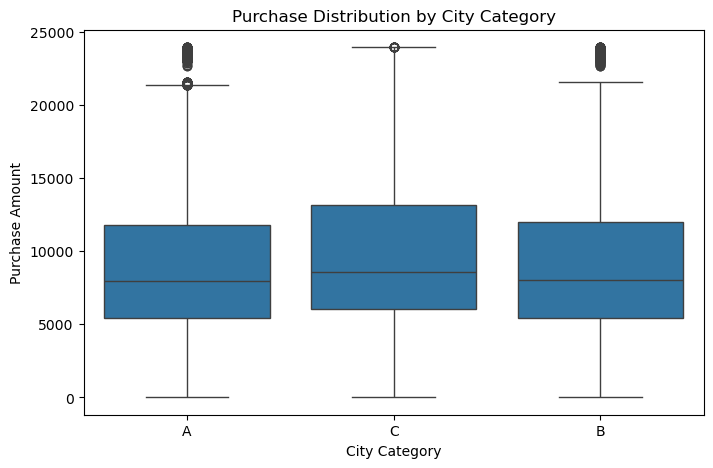

In [59]:
# Visualization:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_black_friday,
    x="City_Category",
    y="Purchase"
)

plt.title("Purchase Distribution by City Category")
plt.xlabel("City Category")
plt.ylabel("Purchase Amount")

plt.show()

In [60]:
# ANOVA:

city_groups = [
    group["Purchase"].values
    for _, group in df_black_friday.groupby("City_Category")
]

f_stat, p_value = f_oneway(*city_groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 1130.7459610102972
P-value: 0.0


In [61]:
# Decision:

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Reject H0


In [63]:
# If significant:

tukey_city = pairwise_tukeyhsd(
    endog=df_black_friday["Purchase"],
    groups=df_black_friday["City_Category"],
    alpha=0.05
)

print(tukey_city)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj  lower    upper   reject
-----------------------------------------------------
     A      B 239.3613   0.0 200.2276  278.495   True
     A      C 807.9818   0.0 766.2598 849.7038   True
     B      C 568.6204   0.0 531.1583 606.0826   True
-----------------------------------------------------


# Assumption Testing ⭐

## A. Independence

- Each transaction should represent an independent observation for the test being applied.

However, our dataset contains multiple transactions from the same customer.

- That's an important limitation.

- "Some customers appear in multiple transactions, so transaction-level observations are not fully independent. This may affect standard errors and should be considered when interpreting inferential results."

## B. Equal variance

- For t-tests/ANOVA, test variance equality.

### For gender:

In [66]:
levene(
    male_purchase,
    female_purchase
)

LeveneResult(statistic=np.float64(1814.0462086524162), pvalue=np.float64(0.0))

### For marital status:

In [68]:
levene(
    single_purchase,
    married_purchase
)

LeveneResult(statistic=np.float64(6.881647103000157), pvalue=np.float64(0.008708767616365338))

### For city:

In [70]:
city_purchase_groups = [
    group["Purchase"].values
    for _, group in df_black_friday.groupby("City_Category")
]

levene(*city_purchase_groups)

LeveneResult(statistic=np.float64(548.5183437870182), pvalue=np.float64(1.0441030768293065e-238))

### Interpretation

#### IF :

p > 0.05

there isn't strong evidence of unequal variances.

#### IF :

p < 0.05

variance differences are present.

That's one reason Welch's t-test is preferable to the equal-variance version for your two-group comparisons.

# Test 5 — City Tenure Correlation

In [79]:
df_black_friday["Stay_Years"] = (
    df_black_friday["Stay_In_Current_City_Years"]
    .astype(str)
    .str.strip()
    .replace("4+", "4")
    .astype(int)
)

In [80]:
df_black_friday[[
    "Stay_In_Current_City_Years",
    "Stay_Years"
]].head()

,Stay_In_Current_City_Years,Stay_Years
0,2,2
1,2,2
2,2,2
3,2,2
4,4+,4


In [81]:
from scipy.stats import pearsonr

corr, p_value = pearsonr(
    df_black_friday["Stay_Years"],
    df_black_friday["Purchase"]
)

print("Correlation:", corr)
print("P-value:", p_value)

Correlation: 0.005422295587475956
P-value: 5.7816177798810326e-05


In [82]:
from scipy.stats import spearmanr

corr_s, p_value_s = spearmanr(
    df_black_friday["Stay_Years"],
    df_black_friday["Purchase"]
)

print("Spearman Correlation:", corr_s)
print("P-value:", p_value_s)

Spearman Correlation: 0.005944147880930414
P-value: 1.0404122836139058e-05


### Interpretation

Correlation is between approximately:

-1 and +1

positive → variables increase together
negative → one increases as the other decreases
near 0 → weak linear/monotonic relationship

##### But:

Correlation does not prove causation.

# Visualize City Tenure Relationship

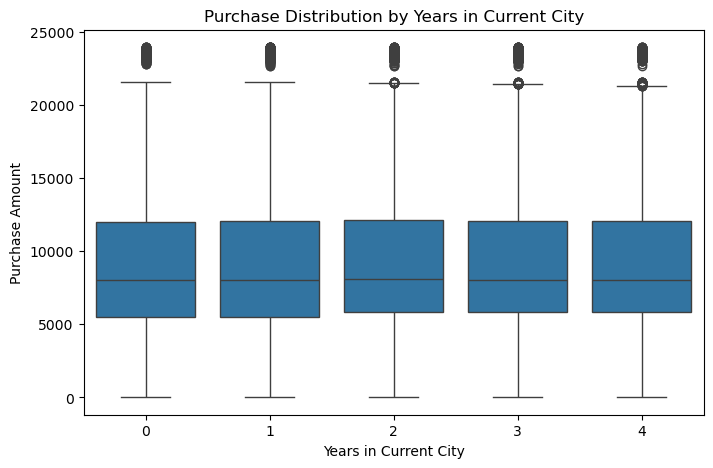

In [84]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_black_friday,
    x="Stay_Years",
    y="Purchase"
)

plt.title("Purchase Distribution by Years in Current City")
plt.xlabel("Years in Current City")
plt.ylabel("Purchase Amount")

plt.show()

# Test 6 — Occupation

## Descriptive analysis

In [87]:
occupation_summary = (
    df_black_friday.groupby("Occupation")["Purchase"]
      .agg(["count", "mean", "sum"])
      .sort_values("mean", ascending=False)
)

occupation_summary.head(10)

,count,mean,sum
Occupation,,,
17,40043,9821.478236,393281453
12,31179,9796.640239,305449446
15,12165,9778.891163,118960211
8,1546,9532.592497,14737388
14,27309,9500.702772,259454692
7,59133,9425.728223,557371587
16,25371,9394.464349,238346955
5,12177,9333.149298,113649759
13,7728,9306.351061,71919481


## Visualization

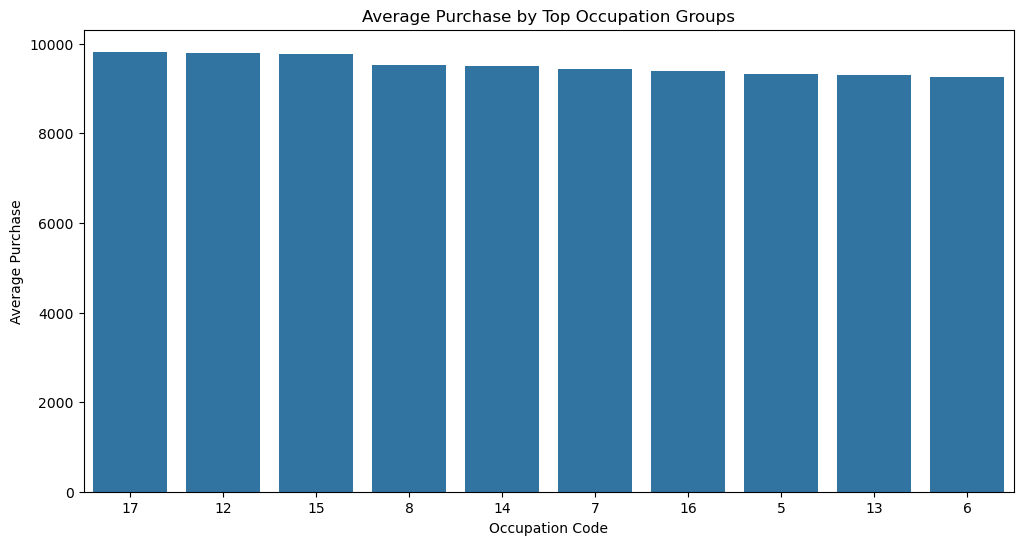

In [89]:
top_occupations = occupation_summary.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_occupations.index.astype(str),
    y=top_occupations["mean"]
)

plt.title("Average Purchase by Top Occupation Groups")
plt.xlabel("Occupation Code")
plt.ylabel("Average Purchase")

plt.show()

## Supplementary correlation

In [91]:
corr, p_value = pearsonr(
    df_black_friday["Occupation"],
    df_black_friday["Purchase"]
)

print("Occupation-Purchase correlation:", corr)
print("P-value:", p_value)

Occupation-Purchase correlation: 0.020832616924612593
P-value: 7.259684172576499e-54


##### "Because Occupation is a categorical code rather than a naturally ordered numerical variable, the correlation coefficient is treated only as supplementary evidence and is not interpreted as a meaningful ordinal relationship."

# Effect Size ⭐

A p-value answers:

Is there evidence of a difference?

Effect size answers:

How large is the difference?

## For gender, calculate Cohen's d:

In [93]:
def cohens_d(group1, group2):
    n1 = len(group1)
    n2 = len(group2)

    s1 = group1.std()
    s2 = group2.std()

    pooled_std = np.sqrt(
        ((n1 - 1) * s1**2 +
         (n2 - 1) * s2**2)
        /
        (n1 + n2 - 2)
    )

    return (group1.mean() - group2.mean()) / pooled_std

In [94]:
gender_d = cohens_d(
    male_purchase,
    female_purchase
)

print("Cohen's d:", gender_d)

Cohen's d: 0.1402018562462025


In [99]:
from scipy.stats import ttest_ind, f_oneway, pearsonr

# -----------------------------
# 1. Gender T-Test
# -----------------------------
male_purchase = df_black_friday.loc[
    df_black_friday["Gender"] == "M", "Purchase"
]

female_purchase = df_black_friday.loc[
    df_black_friday["Gender"] == "F", "Purchase"
]

gender_t_stat, gender_p_value = ttest_ind(
    male_purchase,
    female_purchase,
    equal_var=False
)

# -----------------------------
# 2. Marital Status T-Test
# -----------------------------
single_purchase = df_black_friday.loc[
    df_black_friday["Marital_Status_Label"] == "Single", "Purchase"
]

married_purchase = df_black_friday.loc[
    df_black_friday["Marital_Status_Label"] == "Married", "Purchase"
]

marital_t_stat, marital_p_value = ttest_ind(
    single_purchase,
    married_purchase,
    equal_var=False
)

# -----------------------------
# 3. Age ANOVA
# -----------------------------
age_groups = [
    group["Purchase"].values
    for _, group in df_black_friday.groupby("Age", observed=True)
]

age_f_stat, age_p_value = f_oneway(*age_groups)

# -----------------------------
# 4. City Category ANOVA
# -----------------------------
city_groups = [
    group["Purchase"].values
    for _, group in df_black_friday.groupby("City_Category")
]

city_f_stat, city_p_value = f_oneway(*city_groups)

# -----------------------------
# 5. Stay Years Correlation
# -----------------------------
stay_corr, stay_p_value = pearsonr(
    df_black_friday["Stay_Years"],
    df_black_friday["Purchase"]
)

print("All statistical tests calculated successfully!")

All statistical tests calculated successfully!


In [100]:
print("Gender:", gender_t_stat, gender_p_value)
print("Marital Status:", marital_t_stat, marital_p_value)
print("Age ANOVA:", age_f_stat, age_p_value)
print("City ANOVA:", city_f_stat, city_p_value)
print("Stay Years Correlation:", stay_corr, stay_p_value)

Gender: 46.35824866962607 0.0
Marital Status: 0.3437990512486594 0.7309975627344572
Age ANOVA: 40.5757990945041 1.053563939251671e-49
City ANOVA: 1130.7459610102972 0.0
Stay Years Correlation: 0.005422295587475956 5.7816177798810326e-05


- Effect Size: Negligible / Very Small (less than 0.2)

- Interpretation: There is a minimal difference in purchase amounts between males and females, meaning gender has little to no practical effect on purchasing behavior.

# Statistical Results Table

In [101]:
results = pd.DataFrame({
    "Test": [
        "Gender T-Test",
        "Marital Status T-Test",
        "Age ANOVA",
        "City Category ANOVA",
        "Stay Years Correlation"
    ],
    "Statistic": [
        gender_t_stat,
        marital_t_stat,
        age_f_stat,
        city_f_stat,
        stay_corr
    ],
    "P_Value": [
        gender_p_value,
        marital_p_value,
        age_p_value,
        city_p_value,
        stay_p_value
    ]
})

results["Decision"] = np.where(
    results["P_Value"] < 0.05,
    "Statistically Significant",
    "Not Statistically Significant"
)

results

,Test,Statistic,P_Value,Decision
0,Gender T-Test,46.358249,0.000000e+00,Statistically Significant
1,Marital Status T-Test,0.343799,7.309976e-01,Not Statistically Significant
2,Age ANOVA,40.575799,1.053564e-49,Statistically Significant
3,City Category ANOVA,1130.745961,0.000000e+00,Statistically Significant
4,Stay Years Correlation,0.005422,5.781618e-05,Statistically Significant


## Statistical Decision Framework

- P-value < 0.05
       
- Statistically significant
    
- Reject H0
       
- Measure effect size
       
- Check business relevance
       
- Make business interpretation

- P-value ≥ 0.05
       
- Not statistically significant
       
- Fail to reject H0
       
- Do not claim a meaningful difference

#### Note : Statistical significance + effect size + business magnitude = business significance

# Business Interpretation

### 1. Statistical Result

p-value = ...

### 2. Decision

Reject / Fail to reject H0.

### 3. Business Meaning

What does the result mean for customer behavior?

### 4. Business Action

What could management do with this information?

### Example:

#### Finding: City categories show statistically significant differences in average purchase.

#### Business meaning: Customer purchasing behavior varies across city segments.

#### Business action: Management can consider differentiated marketing and inventory strategies by city category.

# ✅ Final Conclusion

Statistical tests were performed to validate important differences and
relationships identified during exploratory data analysis.

Independent samples t-tests were used to compare purchase behavior across
gender and marital-status groups, while one-way ANOVA was used to assess
differences across age groups and city categories. Correlation analysis was
used to examine the relationship between purchase amount and city tenure,
with occupation treated cautiously because it is represented as a categorical
code.

The statistical results are interpreted using p-values, confidence intervals,
effect sizes, and business relevance rather than statistical significance alone.

The findings from Step 7 will support data-driven customer segmentation,
marketing strategy, city-level planning, and other recommendations in the
next stages of the project.